N	Recursive Time (s)	Iterative Time (s)
1	0.00000010		0.00000030
2	0.00000040		0.00000010
3	0.00000020		0.00000020
4	0.00000040		0.00000020
5	0.00000070		0.00000020
6	0.00000110		0.00000030
7	0.00000180		0.00000030
8	0.00000300		0.00000030
9	0.00000470		0.00000030
10	0.00000760		0.00000030
11	0.00001220		0.00000030
12	0.00002250		0.00000050
13	0.00003910		0.00000040
14	0.00006840		0.00000050
15	0.00008700		0.00000050
16	0.00014120		0.00000070
17	0.00028380		0.00000090
18	0.00035940		0.00000050
19	0.00062010		0.00000080
20	0.00095610		0.00000050
21	0.00150300		0.00000060
22	0.00249250		0.00000070
23	0.00394910		0.00000080
24	0.00651670		0.00000070
25	0.01018690		0.00000090
26	0.01655280		0.00000080
27	0.02691740		0.00000080
28	0.04393370		0.00000080
29	0.07048290		0.00000080
30	0.11378240		0.00000090

N	Recursive Memory (KB)	Iterative Memory (KB)
1	0.0000			0.0781
2	0.0000			0.0781
3	0.0000			0.0781
4	0.0000			0.0781
5	0.0000			0.0781
6	0.0000			0.0781
7	0.0000			0.0781
8	0.0000			0.078

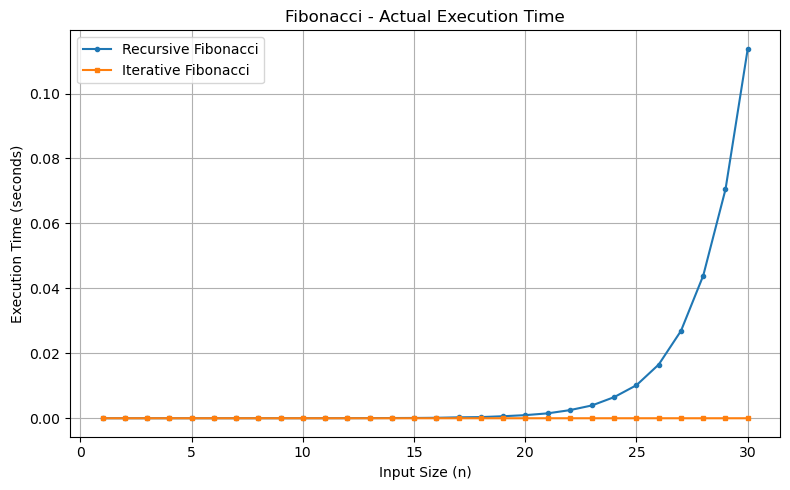

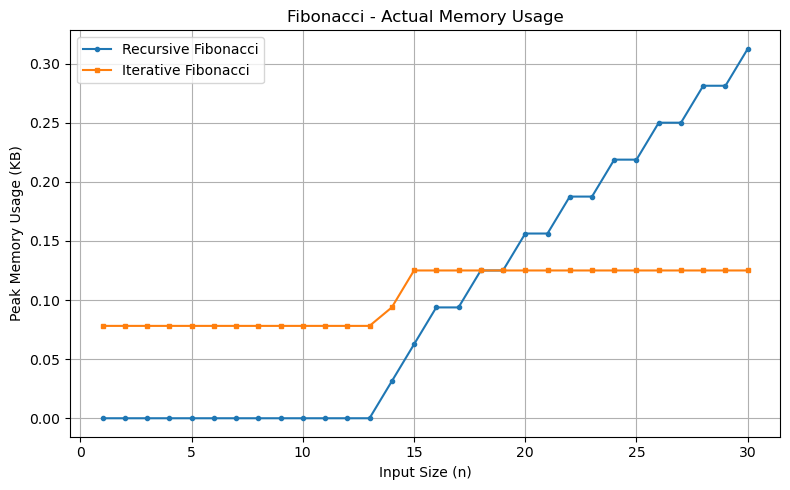

In [ ]:

import matplotlib.pyplot as plt
from time import perf_counter
import tracemalloc
import statistics


def recursive_fibonacci(n):
    if n <= 1:
        return n
    return recursive_fibonacci(n - 1) + recursive_fibonacci(n - 2)


def iterative_fibonacci(n):
    a, b = 0, 1

    for i in range(n):
        a, b = b, a + b

    return a


def measure_time(function, n, repeats=5):
    times = []

    for _ in range(repeats):
        start = perf_counter()
        function(n)
        end = perf_counter()

        times.append(end - start)

    return statistics.median(times)


def measure_memory(function, n, repeats=3):
    memory_values = []

    for _ in range(repeats):
        tracemalloc.start()

        try:
            function(n)
            current, peak = tracemalloc.get_traced_memory()
        finally:
            tracemalloc.stop()

        memory_values.append(peak / 1024)

    return statistics.median(memory_values)


x = list(range(1, 31))

recursive_times = []
iterative_times = []
recursive_memory = []
iterative_memory = []

for n in x:
    # Execution time
    recursive_times.append(
        measure_time(recursive_fibonacci, n)
    )

    iterative_times.append(
        measure_time(iterative_fibonacci, n)
    )

    # Actual peak memory
    recursive_memory.append(
        measure_memory(recursive_fibonacci, n)
    )

    iterative_memory.append(
        measure_memory(iterative_fibonacci, n)
    )


# Display execution times
print("N\tRecursive Time (s)\tIterative Time (s)")
for n, rt, it in zip(x, recursive_times, iterative_times):
    print(f"{n}\t{rt:.8f}\t\t{it:.8f}")


# Display memory usage
print("\nN\tRecursive Memory (KB)\tIterative Memory (KB)")
for n, rm, im in zip(x, recursive_memory, iterative_memory):
    print(f"{n}\t{rm:.4f}\t\t\t{im:.4f}")


# Graph 1: Actual execution time
plt.figure(figsize=(8, 5))

plt.plot(x, recursive_times, marker='o',
         markersize=3, label="Recursive Fibonacci")

plt.plot(x, iterative_times, marker='s',
         markersize=3, label="Iterative Fibonacci")

plt.xlabel("Input Size (n)")
plt.ylabel("Execution Time (seconds)")
plt.title("Fibonacci - Actual Execution Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Graph 2: Actual peak memory usage
plt.figure(figsize=(8, 5))

plt.plot(x, recursive_memory, marker='o',
         markersize=3, label="Recursive Fibonacci")

plt.plot(x, iterative_memory, marker='s',
         markersize=3, label="Iterative Fibonacci")

plt.xlabel("Input Size (n)")
plt.ylabel("Peak Memory Usage (KB)")
plt.title("Fibonacci - Actual Memory Usage")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

